# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AmaanJilani1/flyrank-ml-internship/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

*Lane: Refresh / Content Opportunity Scoring. Label: page impressions fell more than 20% (last 30d vs prior 30d). Language: observed, measured, directional, decision-support.*

## 1. Distributions

**What I see:** every traffic field is heavy-tailed (median page ~800 impressions in the prior 30 days, but the top 10% have 6,800+; the max is in the hundreds of thousands), so I use `log1p` and quartiles, never raw means. Keyword fields (`search_volume`, `competition`, `cpc`) and `word_count` are missing **by content type**, not at random, so I flag missingness instead of filling with 0. About 40% of all pages have <100 impressions in the prior 30 days, so I only score pages that had visibility to lose (**prev-30d impressions ≥ 100**, 18,010 pages).

all pages: 30,000 | eligible (prev30 impressions >= 100): 18,010 | clients: 30 | decline base rate: 0.616
                    count    mean     std    min     50%     90%      99%  \
imp_old           18010.0  3274.2  7604.1    0.0  1093.0  7758.1  33447.5   
imp_prev          18010.0  2955.4  7718.4  100.0   797.0  6782.2  35461.5   
clk_prev          18010.0     9.0    36.2    0.0     1.0    19.0    132.0   
search_volume     17667.0   168.2  1736.5    0.0    10.0   110.0   2900.0   
word_count        12785.0  3448.9  1498.7  692.0  2962.0  5956.6   7578.6   
content_age_days  18010.0   258.9   135.9   90.0   236.0   466.0    545.0   

                       max  
imp_old           258505.0  
imp_prev          218786.0  
clk_prev            1627.0  
search_volume      74000.0  
word_count          9546.0  
content_age_days     564.0  

Missing share by content_type:
                    search_volume  word_count  main_intent
content_type                                              
c

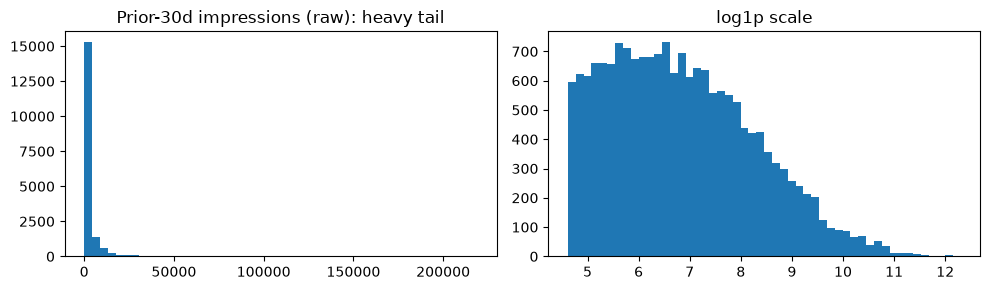

In [9]:

import pandas as pd, numpy as np, os, warnings
warnings.filterwarnings("ignore")
URL = "https://raw.githubusercontent.com/AmaanJilani1/flyrank-ml-internship/main/data/raw/content_refresh_anonymized.csv"
df = pd.read_csv(URL)

# TARGET only. trend_direction is the label source -> never a feature.
df["y"] = (df["trend_direction"] == "down").astype(int)

# Clean past windows. The 90d total = days 1-30 (last30) + 31-60 (prev30) + 61-90 (old).
# Subtracting gives a window that is strictly BEFORE the label window.
for a, b in [("imp", "impressions"), ("clk", "clicks"), ("ses", "sessions")]:
    df[a + "_old"]  = df[b + "_90d"] - df[b + "_last_30d"] - df[b + "_prev_30d"]   # days 61-90 ago
    df[a + "_prev"] = df[b + "_prev_30d"]                                          # days 31-60 ago

# Eligibility: a page can only "decline" if it had visibility to lose.
FLOOR = 100
el = df[df["imp_prev"] >= FLOOR].copy().reset_index(drop=True)
print(f"all pages: {len(df):,} | eligible (prev30 impressions >= {FLOOR}): {len(el):,} "
      f"| clients: {el.client_id.nunique()} | decline base rate: {el.y.mean():.3f}")


def quartile_table(s, label):
    q = pd.qcut(s.rank(method="first"), 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
    t = el.groupby(q, observed=True).y.agg(["size", "mean"]).rename(columns={"mean": "decline_rate"})
    t["range_low"]  = s.groupby(q, observed=True).min().round(2)
    t["range_high"] = s.groupby(q, observed=True).max().round(2)
    print(f"\n{label}  (base rate {el.y.mean():.3f})"); print(t.round(3).to_string())
    return t

print(el[["imp_old", "imp_prev", "clk_prev", "search_volume", "word_count", "content_age_days"]].describe(percentiles=[.5, .9, .99]).round(1).T)
print("\nMissing share by content_type:")
print(df.groupby("content_type")[["search_volume", "word_count", "main_intent"]].agg(lambda s: s.isna().mean()).round(2))
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(el.imp_prev, bins=50); ax[0].set_title("Prior-30d impressions (raw): heavy tail")
ax[1].hist(np.log1p(el.imp_prev), bins=50); ax[1].set_title("log1p scale"); plt.tight_layout(); plt.show()


## 2. Signal test #1 / #2 / #3 (verdict each)

All three signals come from windows **before** the label window.

- **Signal 1 — past momentum** (impressions days 31-60 vs days 61-90). Claim: pages already falling keep falling. **Verdict: CONFIRMED (directional).** The steepest-falling quartile declines at 70.6% vs 55-56% for the flat/growing quartiles (base 61.6%). It is a monotone-ish, ~15-point gap. Note it is an association, not a mechanism: it is partly mean reversion and noise.
- **Signal 2 — volume** (prior-30d impressions). Claim: bigger pages are more at risk. **Verdict: MIXED.** Rates run 61.5%, 65.1%, 63.1%, 56.6%: not monotone, and the biggest pages decline *least*. Volume is a priority multiplier (more to lose), not a risk signal.
- **Signal 3 — content age.** Claim: older content decays more. **Verdict: OPPOSITE for the oldest quartile.** Rates run 66.6%, 73.7%, 61.2%, 44.8%: the oldest pages (>347 days) decline *least*. Non-monotone, so age alone is not a safe rule.

In [10]:

t1 = quartile_table(np.log1p(el.imp_prev) - np.log1p(el.imp_old), "Signal 1: past momentum (log change, prev30 vs old30; low = falling)")
t2 = quartile_table(np.log1p(el.imp_prev), "Signal 2: volume (log prior-30d impressions)")
t3 = quartile_table(el.content_age_days, "Signal 3: content_age_days")



Signal 1: past momentum (log change, prev30 vs old30; low = falling)  (base rate 0.616)
              size  decline_rate  range_low  range_high
Q1 (lowest)   4503         0.706      -4.44       -0.61
Q2            4502         0.640      -0.61       -0.24
Q3            4502         0.555      -0.24        0.14
Q4 (highest)  4503         0.563       0.14        8.21

Signal 2: volume (log prior-30d impressions)  (base rate 0.616)
              size  decline_rate  range_low  range_high
imp_prev                                               
Q1 (lowest)   4503         0.615       4.62        5.68
Q2            4502         0.651       5.68        6.68
Q3            4502         0.631       6.68        7.81
Q4 (highest)  4503         0.566       7.81       12.30

Signal 3: content_age_days  (base rate 0.616)
                  size  decline_rate  range_low  range_high
content_age_days                                           
Q1 (lowest)       4503         0.666         90         131
Q2 

## 3. The flag-linked test

**Flag tested:** the `REFRESH if stale >= 180 days and visible` rule (the logic behind my ML-07 baseline and FlyRank-style freshness flags). **Assumption:** old = more likely to decline.

**Verdict: FALSE as a general rule (correcting my earlier "CONFIRMED").** Across all 30,000 pages, pages not updated for 180+ days decline *less* than average (47.1% vs 54.2%). The earlier quartile table I used looked flat (0.539 / 0.546 / 0.547) and I should not have called that confirmed. The rule only looks good on a tiny slice: the stale **and** visible pages (21 of them) decline ~95% of the time, but that is 21 pages from only 7 clients, so it cannot support a general rule.

In [11]:

stale = df.days_since_last_update >= 180
print(f"ALL pages   stale>=180d: n={stale.sum():>3}  decline rate {df[stale].y.mean():.3f}   (all-page base {df.y.mean():.3f})")
print(df.groupby(pd.cut(df.days_since_last_update, [0, 30, 90, 180, 400]), observed=True).y.agg(["size", "mean"]).round(3).to_string())
vis = el[el.days_since_last_update >= 180]
print(f"\nELIGIBLE & stale>=180d: n={len(vis)}  decline rate {vis.y.mean():.3f}  from {vis.client_id.nunique()} client(s)")
print("-> tiny, clustered slice. Not enough to promote 'stale' into a universal rule.")


ALL pages   stale>=180d: n=174  decline rate 0.471   (all-page base 0.542)
                         size   mean
days_since_last_update              
(0, 30]                 20480  0.511
(30, 90]                  175  0.589
(90, 180]                9171  0.611
(180, 400]                174  0.471

ELIGIBLE & stale>=180d: n=21  decline rate 0.952  from 7 client(s)
-> tiny, clustered slice. Not enough to promote 'stale' into a universal rule.


## 4. What this means in practice

A content team should not use age or staleness alone to pick refresh candidates: older pages decline less here, not more. The most usable early-warning signal is **a page that was already losing impressions in the prior 60 days** (directional, ~15 points above the flat group). Treat volume as a priority weight (more traffic at stake), not as evidence of decay, and treat all of this as observed association, not a cause.

In [12]:

print("Take-away table (decline rate, eligible pages):")
print(pd.DataFrame({"signal": ["past momentum", "volume", "content age", "stale>=180d (all pages)"],
                    "verdict": ["CONFIRMED (directional)", "MIXED", "OPPOSITE (oldest quartile)", "FALSE"]}).to_string(index=False))


Take-away table (decline rate, eligible pages):
                 signal                    verdict
          past momentum    CONFIRMED (directional)
                 volume                      MIXED
            content age OPPOSITE (oldest quartile)
stale>=180d (all pages)                      FALSE


## Self-check

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.